<a href="https://colab.research.google.com/github/rabicenkonikita3-cloud/python-practice-algos/blob/master/hw_8_rabichencko_11_11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [17]:
import os
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import f1_score, precision_recall_curve, auc, classification_report


In [20]:
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
data = pd.read_csv(os.path.join(path, "creditcard.csv"))

scaler = StandardScaler()
data[['Time', 'Amount']] = scaler.fit_transform(data[['Time', 'Amount']])

X = data.drop('Class', axis=1)
y = data['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

normal_train = X_train[y_train == 0]

print("Размер train:", X_train.shape)
print("Размер test:", X_test.shape)


Using Colab cache for faster access to the 'creditcardfraud' dataset.
Размер train: (227845, 30)
Размер test: (56962, 30)


In [21]:
iso = IsolationForest(
    n_estimators=200,
    max_samples=256,
    contamination=0.00172,
    random_state=42,
    n_jobs=-1,
)
iso.fit(normal_train)

labels = iso.predict(X_test)
scores = -iso.score_samples(X_test)
y_pred = (labels == -1).astype(int)

print(f"Аномалий: {(labels == -1).sum()} из {len(labels)}")
print(classification_report(y_test, y_pred))

pred_iso = y_pred
score_iso = scores


Аномалий: 126 из 56962
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.21      0.27      0.23        98

    accuracy                           1.00     56962
   macro avg       0.60      0.63      0.62     56962
weighted avg       1.00      1.00      1.00     56962



In [22]:
lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.00172,
    novelty=True,
    n_jobs=-1,
)
lof.fit(normal_train)

labels = lof.predict(X_test)
scores = -lof.decision_function(X_test)
y_pred = (labels == -1).astype(int)

print(f"Аномалий: {(labels == -1).sum()} из {len(labels)}")
print(classification_report(y_test, y_pred))

pred_lof = y_pred
score_lof = scores


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


Аномалий: 102 из 56962
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.00      0.00      0.00        98

    accuracy                           1.00     56962
   macro avg       0.50      0.50      0.50     56962
weighted avg       1.00      1.00      1.00     56962



Isolation Forest -> F1: 0.2321 PR-AUC: 0.1241
LOF -> F1: 0.0 PR-AUC: 0.0065


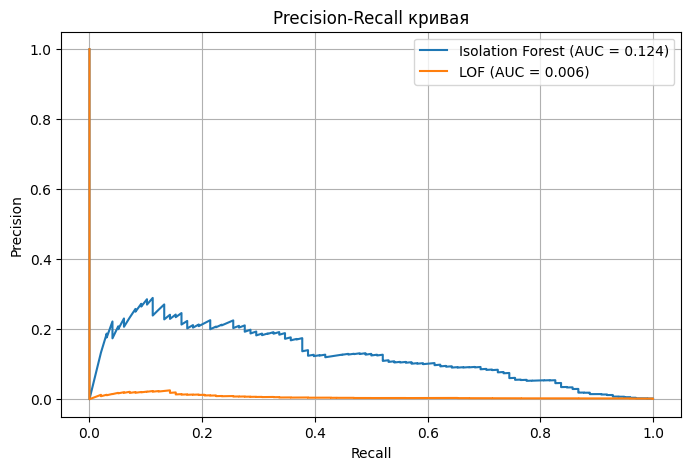

In [23]:
f1_iso = f1_score(y_test, pred_iso)
f1_lof = f1_score(y_test, pred_lof)

p_iso, r_iso, _ = precision_recall_curve(y_test, score_iso)
auc_iso = auc(r_iso, p_iso)

p_lof, r_lof, _ = precision_recall_curve(y_test, score_lof)
auc_lof = auc(r_lof, p_lof)

print("Isolation Forest -> F1:", round(f1_iso, 4), "PR-AUC:", round(auc_iso, 4))
print("LOF -> F1:", round(f1_lof, 4), "PR-AUC:", round(auc_lof, 4))

plt.figure(figsize=(8, 5))
plt.plot(r_iso, p_iso, label=f'Isolation Forest (AUC = {auc_iso:.3f})')
plt.plot(r_lof, p_lof, label=f'LOF (AUC = {auc_lof:.3f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall кривая')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
Вывод;
Isolation Forest справился лучше, у него выше F1 и PR-AUC.На больших таблицаах он работает стабильнее,а LOF теряется из-за большого количества столбцов

ROC-AUC здесь обманывает из-за перекоса в данных. Обычных операций слишoком много, и на их фоне ошибки почти не портят результат, поэтому правильнее смотреть на PR-AUC

Если снизить contamination до 0.001, модель станет строже и будет искать только самые явные выбросы.Precision вырастет, потому что станет меньшеt ложных срабатываний, а Recall упадет, так как часть мошенников модель пропустит